# Multimodal Generation com BLIP - Funcionamento para o Colab
## Aplicação Python independente: gerar legendas para fotos

**Entrada:** imagem; opcionalmente um início de frase. **Saída:** texto gerado.

Um único modelo pré-treinado: `Salesforce/blip-image-captioning-base`. O experimento padrão usa **1 foto e 2 gerações curtas**. Funciona em CPU; GPU é opcional e ajuda na latência. Não há treinamento, geração de imagens ou outros modelos avaliadores.

**Outra aplicação, apresentada separadamente:** [Qwen-Image-Edit no Hugging Face](https://huggingface.co/spaces/Qwen/Qwen-Image-Edit), que faz imagem + instrução → imagem editada. O notebook NÃO chama esse Space, não usa Qwen e não depende dele. O Hub serve apenas para baixar os pesos BLIP.

### Como rodar no Colab
1. Execute a instalação. Se o Transformers já estava importado, reinicie a sessão e continue depois dela.
2. Execute as células em ordem. GPU é opcional.
3. O exemplo já tem uma foto pública; para usar a sua, ative `USAR_UPLOAD=True`.
4. Compare as duas legendas, confira os tempos e avalie visualmente.
5. Baixe o ZIP ao final.

**Tempo:** a primeira carga baixa cerca de 990 MB de pesos e depende da conexão. A inferência é curta por projeto, mas o tempo real precisa ser medido no seu Colab. Instalação e inferência dos pesos ainda não foram executadas nesta revisão; não há resultados inventados.


## 1 Instalar dependências
O PyTorch do Colab é preservado. A versão 4.x mantém a API documentada utilizada. Em caso de conflito torch/torchvision, use uma sessão limpa; não reinstale versões aleatórias dos dois pacotes.

O `pip install` dá um erro na primeira execução, mas é validado.


In [2]:
%pip -q install "transformers==4.49.0" huggingface_hub tokenizers pillow requests pandas matplotlib


## 2 Carregar o único modelo
O cronômetro abaixo inclui download e inicialização, quando necessários. Esse tempo é registrado separado da geração de cada legenda. A precisão float32 é mantida para simplificar o uso em CPU e GPU.


In [ ]:
import io,json,time,platform,importlib.metadata,shutil,re
from pathlib import Path
import torch
import pandas as pd
import requests
import matplotlib.pyplot as plt
from PIL import Image,ImageOps
from IPython.display import display
from transformers import BlipProcessor,BlipForConditionalGeneration

MODEL_ID="Salesforce/blip-image-captioning-base"
DEVICE="cuda" if torch.cuda.is_available() else "cpu"
MAX_NEW_TOKENS=24
OUT=Path("outputs_blip");OUT.mkdir(exist_ok=True)
t0=time.perf_counter()
processor=BlipProcessor.from_pretrained(MODEL_ID)
model=BlipForConditionalGeneration.from_pretrained(MODEL_ID).to(DEVICE).eval()
if DEVICE=="cuda":torch.cuda.synchronize()
load_seconds=time.perf_counter()-t0
environment={"model":MODEL_ID,"model_revision":getattr(model.config,"_commit_hash",None),
             "device":DEVICE,"python":platform.python_version(),
             "torch":torch.__version__,"transformers":importlib.metadata.version("transformers"),
             "load_seconds":load_seconds,"max_new_tokens":MAX_NEW_TOKENS,
             "num_beams":1,"do_sample":False}
(OUT/"environment.json").write_text(json.dumps(environment,indent=2),encoding="utf-8")
print("Dispositivo:",DEVICE)
print(f"Carregamento do modelo (com download se necessário): {load_seconds:.2f} s")
print("Pesos carregados uma única vez. O exemplo fará só duas gerações.")


Dispositivo: cpu
Carregamento do modelo (com download se necessário): 3.90 s
Pesos carregados uma única vez. O exemplo fará só duas gerações.


## 3 Escolher uma foto
Por padrão, usa a imagem da demonstração oficial BLIP: uma mulher com um cachorro na praia. A lista de palavras-chave é uma referência manual de conteúdo, não uma legenda produzida nesta revisão. A foto oficial é útil para testar funcionamento, mas não é um teste independente de generalização.

Para usar sua foto, altere `USAR_UPLOAD=True`. Nesse caso, preencha as palavras-chave depois de olhar a imagem; a lista do exemplo não será reaproveitada.


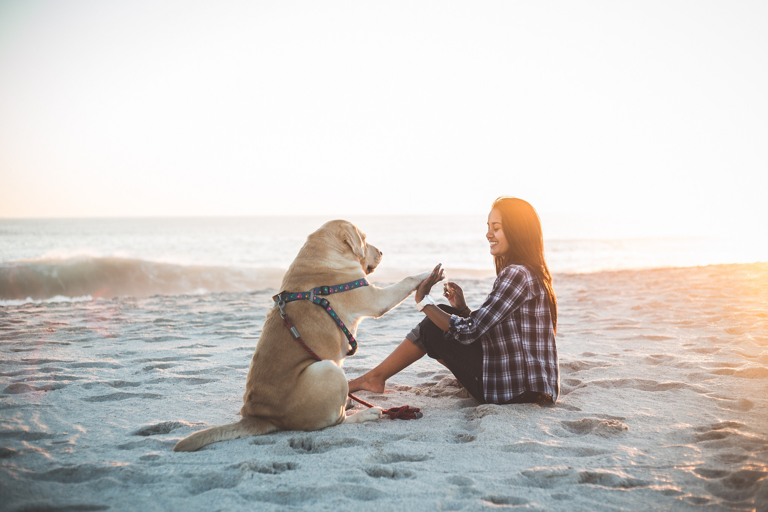

In [ ]:
USAR_UPLOAD=False
URL_EXEMPLO="https://storage.googleapis.com/sfr-vision-language-research/BLIP/demo.jpg"
if USAR_UPLOAD:
    from google.colab import files
    uploaded=files.upload()
    if not uploaded:raise ValueError("Nenhuma foto foi enviada. Execute esta célula novamente.")
    name=next(iter(uploaded))
    image=Image.open(io.BytesIO(uploaded[name]))
    KEYWORDS=[]              # Exemplo para outra foto: ["cat", "table"]
    image_source="foto enviada: "+name
else:
    response=requests.get(URL_EXEMPLO,timeout=30)
    response.raise_for_status()
    image=Image.open(io.BytesIO(response.content))
    KEYWORDS=["woman","dog"]
    image_source=URL_EXEMPLO
image=ImageOps.exif_transpose(image).convert("RGB")
image.thumbnail((768,768))
IMAGE_PATH=OUT/"entrada.png";image.save(IMAGE_PATH)
(OUT/"input_metadata.json").write_text(json.dumps({"source":image_source,"keywords":KEYWORDS},ensure_ascii=False,indent=2),encoding="utf-8")
display(image)


## 4 Gerar a legenda
O prefixo é o **começo da frase a completar**, não um comando de chat. Use inglês, idioma do checkpoint. A legenda decodificada pode incluir o prefixo. Busca gulosa (`num_beams=1`, sem amostragem) e limite de 24 tokens novos reduzem trabalho. Um texto pode parar antes do limite.


In [ ]:
@torch.inference_mode()
def legendar(caminho,prefixo=""):
    photo=ImageOps.exif_transpose(Image.open(caminho)).convert("RGB")
    photo.thumbnail((768,768))
    if prefixo.strip():
        inputs=processor(images=photo,text=prefixo,return_tensors="pt").to(DEVICE)
    else:
        inputs=processor(images=photo,return_tensors="pt").to(DEVICE)
    if DEVICE=="cuda":torch.cuda.synchronize()
    start=time.perf_counter()
    generated=model.generate(**inputs,max_new_tokens=MAX_NEW_TOKENS,num_beams=1,do_sample=False)
    if DEVICE=="cuda":torch.cuda.synchronize()
    seconds=time.perf_counter()-start
    caption=processor.decode(generated[0],skip_special_tokens=True).strip()
    return caption,seconds

experiments=[("livre",""),("com_prefixo","a photo of")]
rows=[]
for mode,prefix in experiments:
    caption,seconds=legendar(IMAGE_PATH,prefix)
    rows.append({"modo":mode,"prefixo":prefix,"legenda":caption,"geracao_segundos":seconds})
    print(f"\n{mode} ({seconds:.2f} s): {caption}")
results=pd.DataFrame(rows)
results.to_csv(OUT/"legendas.csv",index=False)
display(results)
# Demonstração ao vivo após carregar o modelo:
# texto,tempo=legendar(IMAGE_PATH,"a picture of")
# print(texto,tempo)



livre (6.86 s): a woman sitting on the beach with her dog

com_prefixo (4.13 s): a photo of a woman and her dog on the beach


,modo,prefixo,legenda,geracao_segundos
0,livre,,a woman sitting on the beach with her dog,6.857110
1,com_prefixo,a photo of,a photo of a woman and her dog on the beach,4.132428


In [ ]:
legendar(IMAGE_PATH, "")  # aquecimento, não entra na tabela
prefixos = ["a close up of", "the woman is", "the dog is", "in the background, we can see"]
rows = []
for p in prefixos:
    legenda, seg = legendar(IMAGE_PATH, p)
    rows.append({"prefixo": p, "legenda": legenda, "geracao_segundos": seg})
    print(f"[{p}] -> {legenda} ({seg:.2f} s)")
pd.DataFrame(rows).to_csv(OUT / "legendas_prefixos.csv", index=False)

[a close up of] -> a close up of a woman sitting on the beach with a dog (4.01 s)
[the woman is] -> the woman is sitting on the beach with her dog (3.79 s)
[the dog is] -> the dog is sitting on the beach (2.78 s)
[in the background, we can see] -> in the background, we can see a woman sitting on the beach with a dog (4.04 s)


## 5 Avaliação simples e transparente
Métrica de desempenho: tempo só de `model.generate`, separado do download, leitura da foto e pré-processamento. A primeira inferência pode incluir aquecimento; duas medidas não permitem concluir qual modo é mais rápido.

A cobertura de palavras-chave abaixo é **lexical**: indica quantas classes da lista aparecem na legenda, sem validar que sejam verdadeiras. Pode errar por sinônimos, omissão, negação ou alucinação. Não é acurácia do BLIP. Não se mede F1 de um detector nem qualidade de imagem neste experimento.


,modo,legenda,geracao_segundos,cobertura_lexical
0,livre,a woman sitting on the beach with her dog,6.857110,1.0
1,com_prefixo,a photo of a woman and her dog on the beach,4.132428,1.0


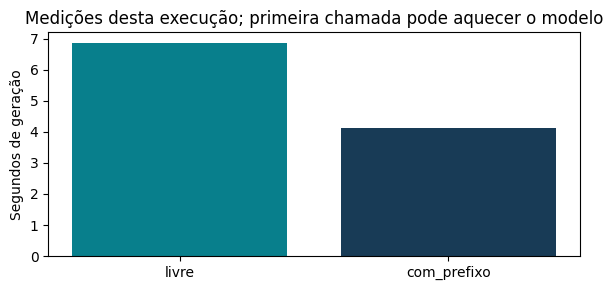

Carregamento separado: 3.9 s


In [ ]:
def cobertura_lexical(texto,keywords):
    if not keywords:return None
    lower=texto.lower()
    return sum(bool(re.search(r"\b"+re.escape(k.lower())+r"\b",lower)) for k in keywords)/len(keywords)

results["cobertura_lexical"]=results.legenda.apply(lambda text:cobertura_lexical(text,KEYWORDS))
results.to_csv(OUT/"legendas.csv",index=False)
display(results[["modo","legenda","geracao_segundos","cobertura_lexical"]])
fig,ax=plt.subplots(figsize=(6,3))
ax.bar(results.modo,results.geracao_segundos,color=["#087F8C","#183B56"])
ax.set_ylabel("Segundos de geração");ax.set_title("Medições desta execução; primeira chamada pode aquecer o modelo")
plt.tight_layout();plt.savefig(OUT/"tempos.png",dpi=150);plt.show()
print("Carregamento separado:",round(load_seconds,2),"s")


## 6 Conferência humana
Olhe a foto e preencha cada `None` com `1` (sim) ou `0` (não). “Sujeito correto” verifica o elemento central; “sem detalhe inventado” verifica se os detalhes afirmados são sustentados pela foto; “frase compreensível” verifica legibilidade. O modelo não preenche suas próprias notas. Não confundir a média dessa pequena rubrica com acurácia geral.

Para uma avaliação acadêmica melhor, repita com duas fotos próprias diferentes e registre ao menos um acerto e qualquer erro observado, sem prometer que o modelo falhará.


In [ ]:
notas={
 "livre":{"sujeito_correto":None,"sem_detalhe_inventado":None,"frase_compreensivel":None},
 "com_prefixo":{"sujeito_correto":None,"sem_detalhe_inventado":None,"frase_compreensivel":None},
}
for mode,scores in notas.items():
    for criterion,value in scores.items():
        if value is not None and (type(value) is not int or value not in (0,1)):
            raise ValueError(f"Nota inválida: {mode}/{criterion}. Use 0, 1 ou None.")
human=pd.DataFrame.from_dict(notas,orient="index").rename_axis("modo").reset_index()
avaliacao=results.merge(human,on="modo",validate="one_to_one")
criteria=["sujeito_correto","sem_detalhe_inventado","frase_compreensivel"]
complete=avaliacao[criteria].notna().all(axis=1)
avaliacao["nota_rubrica"]=avaliacao[criteria].apply(pd.to_numeric).mean(axis=1).where(complete)
avaliacao.to_csv(OUT/"avaliacao_humana.csv",index=False)
display(avaliacao)
if not complete.any():print("Preencha as notas humanas para obter a média da rubrica.")


,modo,prefixo,legenda,geracao_segundos,cobertura_lexical,sujeito_correto,sem_detalhe_inventado,frase_compreensivel,nota_rubrica
0,livre,,a woman sitting on the beach with her dog,6.857110,1.0,None,None,None,NaN
1,com_prefixo,a photo of,a photo of a woman and her dog on the beach,4.132428,1.0,None,None,None,NaN


Preencha as notas humanas para obter a média da rubrica.


## 7 Exportar os resultados
O ZIP contém foto de entrada, origem, configuração, legendas, tempos, gráfico e notas humanas existentes. Fechar a sessão do Colab pode apagar arquivos não baixados. As legendas podem omitir informação ou afirmar detalhes que não aparecem na imagem; use revisão humana antes de aplicá-las como texto alternativo.


In [ ]:
archive=shutil.make_archive("resultados_blip","zip",root_dir=OUT)
print("Arquivo:",archive)
try:
    from google.colab import files
    files.download(archive)
except ImportError:
    print("Fora do Colab, baixe o ZIP pelo explorador de arquivos.")


Arquivo: /content/resultados_blip.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 8 Aplicação externa separada
**Qwen-Image-Edit:** https://huggingface.co/spaces/Qwen/Qwen-Image-Edit

Recebe uma foto e uma instrução e gera uma foto editada. Apresentar no navegador como uma aplicação existente diferente do nosso legendador. Os tempos e resultados do Space não entram nas tabelas BLIP.

### Fontes
- BLIP: Junnan Li, Dongxu Li, Caiming Xiong e Steven Hoi (2022): https://arxiv.org/abs/2201.12086
- Checkpoint e exemplo de legenda condicional: https://huggingface.co/Salesforce/blip-image-captioning-base
- API utilizada: https://huggingface.co/docs/transformers/v4.49.0/en/model_doc/blip

**Escopo da revisão:** sintaxe, preparação dos dados e lógica de métricas/exportação podem ser testadas sem pesos. Inferência real e duração ainda exigem executar o notebook em um ambiente com as dependências e acesso aos pesos. Não há resultados pré-preenchidos.
